In [ ]:
from ydata_profiling import ProfileReport
import pandas as pd
import sys
import os

base_dir = os.getcwd()
level_up = os.path.abspath(os.path.join(base_dir,'..'))

sys.path.insert(0,f'{base_dir}/..')

pd.set_option("display.max_columns",500)

# Exploratory Analysis
data_path = os.path.join(level_up,'datasets','titanic')
data_list = os.listdir(data_path)


Exploratory Analysis

In [ ]:
datasets = {'name':[],'data':[]}
for data in data_list:
    df = pd.read_csv(rf'{data_path}/{data}')
    datasets['name'].append(data)
    datasets['data'].append(df)

train = datasets['data'][datasets['name'].index('train.csv')]
test = datasets['data'][datasets['name'].index('test.csv')]

generate_profile = False # set true to generate profillers
if generate_profile:
    train_profile = ProfileReport(train, title="Train Profile")
    train_profile.to_file(f'{base_dir}/data_profiles/titanic_train.html')

    test_profile = ProfileReport(train, title="Test Profile")
    test_profile.to_file(f'{base_dir}/data_profiles/titanic_test.html')


Insights:

![alt text](cabin_col.jpg)

Cabin column with 77.1% missing values
Action: remove for training and testing

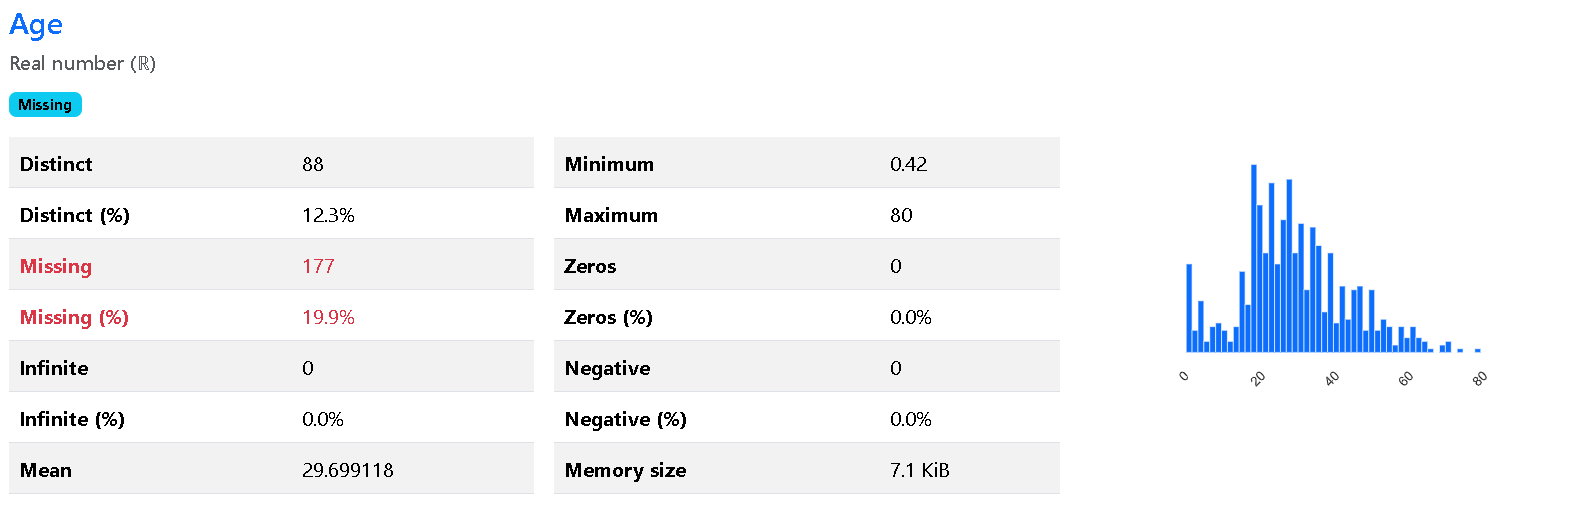

Age also has 177 missing values. Let's remove this values from the train dataset and compare the information gain with the original one:

In [ ]:
import numpy as np

def entropy(serie):
    p = serie.value_counts(normalize=True)
    return -(p * np.log2(p)).sum()

def information_gain(df, feature, target):
    sub = df[[feature, target]].dropna()
    h_cond = sum(
        len(g) / len(sub) * entropy(g[target])
        for _, g in sub.groupby(feature, observed=True)
    )
    return entropy(sub[target]) - h_cond

def gain_dataset(df, target, ignorar=()):
    return pd.Series({
        c: information_gain(df, c, target)
        for c in df.columns if c != target and c not in ignorar
    })

target = 'Survived'
train = train.drop('Cabin',axis=1)
train_mask = train.dropna(subset=['Age']).copy()

target = "Survived"   
bin_rule = "fd"           
max_categories = 20  
id_ratio = 0.9

reference = train

def classify_columns(df, target, max_categories, id_ratio):
    """Classify each column using only the data in `df`."""
    continuous, identifiers = [], []
    for col in df.columns:
        if col == target:
            continue
        s = df[col].dropna()
        if len(s) == 0:
            continue
        if s.nunique() / len(s) > id_ratio:
            identifiers.append(col)
        elif pd.api.types.is_numeric_dtype(s) and s.nunique() > max_categories:
            continuous.append(col)
    return continuous, identifiers

def learn_bin_edges(df, columns, rule):
    """Learn bin edges from the reference data only."""
    edges = {}
    for col in columns:
        e = np.histogram_bin_edges(df[col].dropna(), bins=rule)
        e[0], e[-1] = -np.inf, np.inf  # values outside the reference range don't become NaN
        edges[col] = e
    return edges

continuous_cols, ignore_cols = classify_columns(reference, target, max_categories, id_ratio)
bin_edges = learn_bin_edges(reference, continuous_cols, bin_rule)

def prepare(df):
    """Apply the SAME reference-derived edges to any dataset."""
    d = df.copy()
    for col, e in bin_edges.items():
        d[col] = pd.cut(d[col], bins=e)
    return d

g_train = gain_dataset(prepare(train), target, ignore_cols)
g_mask  = gain_dataset(prepare(train_mask), target, ignore_cols)

comp = pd.DataFrame({
    "train": g_train,
    "train_mask": g_mask,
    "difference": g_mask - g_train,
    "difference_%": (g_mask - g_train) / g_train * 100,
})

print("Continuous (binned):", continuous_cols)
print("Ignored (identifiers):", ignore_cols)
print({c: len(e) - 1 for c, e in bin_edges.items()}, "<- number of bins per column")
print(comp)
print("Sum train:", g_train.sum(), "| Sum train_mask:", g_mask.sum())
print(train_mask.columns)

Continuous (binned): ['Age', 'Fare']
Ignored (identifiers): ['PassengerId', 'Name']
{'Age': 20, 'Fare': 107} <- number of bins per column
             train  train_mask  difference  difference_%
Pclass    0.083831    0.095680    0.011849     14.134668
Sex       0.217660    0.216016   -0.001644     -0.755327
Age       0.036438    0.036438    0.000000      0.000000
SibSp     0.033466    0.024433   -0.009033    -26.991980
Parch     0.023611    0.030069    0.006458     27.354166
Ticket    0.825937    0.831530    0.005593      0.677126
Fare      0.129128    0.136858    0.007730      5.986327
Embarked  0.020987    0.027858    0.006871     32.737141
Sum train: 1.3710582820268122 | Sum train_mask: 1.3988820833795619
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Embarked'],
      dtype='object')


**Conclusion:** Removing the 177 rows with missing `Age` values had little effect on
the information gain of the main features (`Sex`, `Pclass`). Therefore, these rows
will be removed.

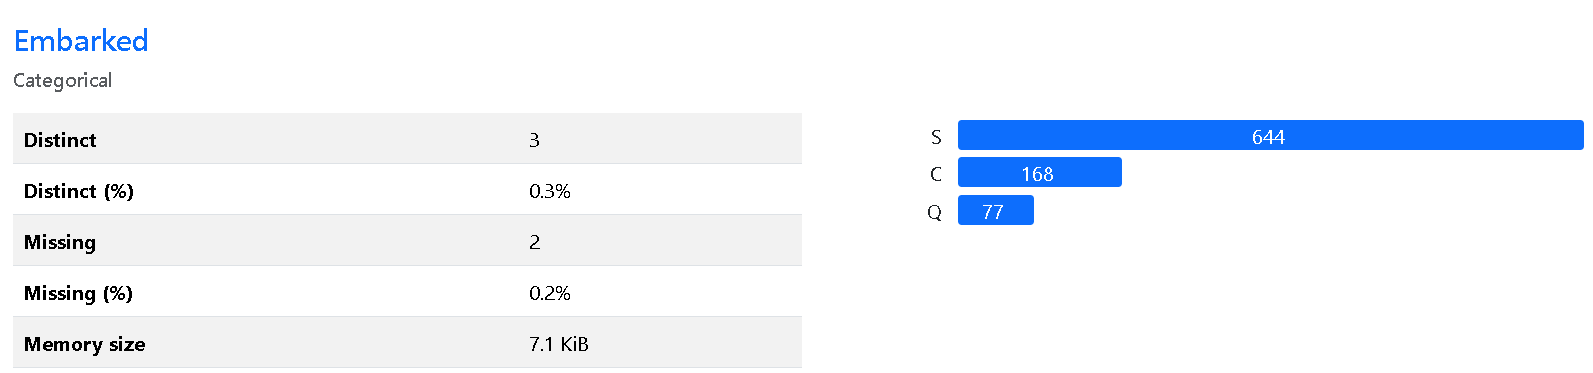

The 'Embarked' and 'Sex' columns will be encoded and used:
'Embarked': S = 0 C = 1 Q = 2
'Sex': male = 0 female 1

In [23]:

train_mask['Embarked'] = train_mask['Embarked'].replace({'S':0,'C':1,'Q':2})
train_mask['Sex'] = train_mask['Sex'].replace({'male':0,'female':1,'Q':2})

C:\Users\guiul\AppData\Local\Temp\ipykernel_13756\516438953.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_mask['Embarked'] = train_mask['Embarked'].replace({'S':0,'C':1,'Q':2})
C:\Users\guiul\AppData\Local\Temp\ipykernel_13756\516438953.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_mask['Sex'] = train_mask['Sex'].replace({'male':0,'female':1,'Q':2})


In [24]:
# Final train_mask:
train_mask = train_mask.drop(columns=['PassengerId','Name','Ticket'],axis=1)

# Adjusting test mask:
test_mask = test.copy()
# test_mask = test_mask.dropna(subset='Age')
test_mask = test_mask.drop(columns=['Name','Ticket','Cabin'],axis=1)
test_mask['Embarked'] = test_mask['Embarked'].replace({'S':0,'C':1,'Q':2})
test_mask['Sex'] = test_mask['Sex'].replace({'male':0,'female':1,'Q':2})

train_mask.to_csv(f'{base_dir}/consolidated_data/train_consolidated.csv',index=0)
test_mask.to_csv(f'{base_dir}/consolidated_data/test_consolidated.csv',index=0)


C:\Users\guiul\AppData\Local\Temp\ipykernel_13756\2393164191.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_mask['Embarked'] = test_mask['Embarked'].replace({'S':0,'C':1,'Q':2})
C:\Users\guiul\AppData\Local\Temp\ipykernel_13756\2393164191.py:9: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_mask['Sex'] = test_mask['Sex'].replace({'male':0,'female':1,'Q':2})
